# Source Code

In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg as la

## Marchenko-Pastur Law

In [2]:
def generate_random_normal(p, n):
    return np.random.normal(0, 1, size=(p, n))

def compute_singular_values(matrix): 
    p, n = matrix.shape
    covariance_matrix = np.matmul(matrix, np.transpose(matrix)) / n

    return la.eigvalsh(covariance_matrix)

def compute_marchenko_pastur(gamma, step=1000):
    a_plus = (1 + math.sqrt(gamma)) ** 2
    a_minus = (1 - math.sqrt(gamma)) ** 2
    
    x_values = np.linspace(a_minus, a_plus, step)
    y_values = np.sqrt((a_plus - x_values) * (x_values - a_minus)) / (2 * np.pi * gamma * x_values)

    point_mass = 1.0 - (1.0 / gamma) if gamma > 1 else None

    return point_mass, x_values, y_values
        
# The helper function below creates tthe histogram of the singular values of a matrix and 
# the marchenko pastur distribution on the same plot.

def generate_plot(matrix):
    singular_values = compute_singular_values(matrix)
    plt.hist(singular_values, bins=30, color='skyblue', edgecolor='black', density=True)

    p, n = matrix.shape
    gamma = p / n
    
    point_mass, x_values, y_values = compute_marchenko_pastur(gamma)
    plt.plot(x_values, y_values, color='red')

    if point_mass:
        plt.vlines(0, 0, point_mass, color="red")
        plt.plot(0, point_mass, "ro", markersize=8)

    plt.show()

### Testing

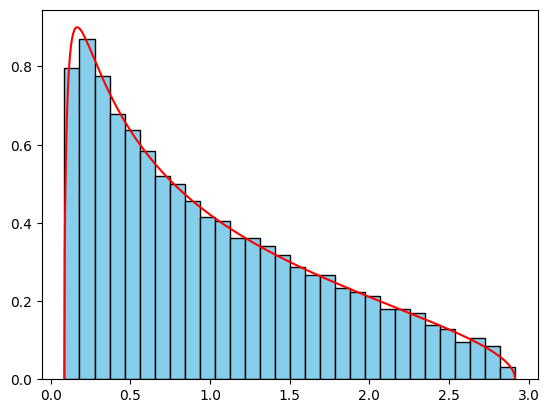

In [3]:
matrix = generate_random_normal(1000, 2000)
generate_plot(matrix)

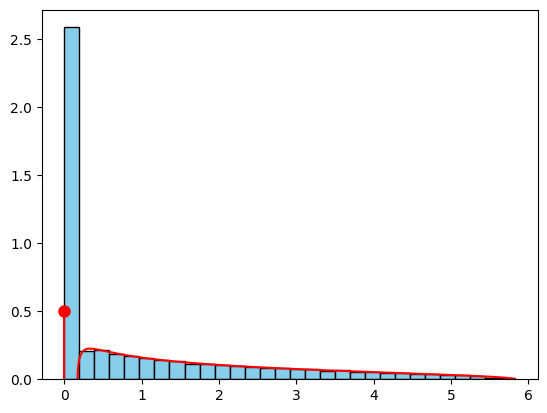

In [4]:
matrix = generate_random_normal(2000, 1000)
generate_plot(matrix)

## Neural Network

### Dense Layer

In [5]:
class DenseLayer:
    def __init__(self, input_dim, output_dim):
        # He initialization for weights, biases initialized to zeros
        self.weights = np.random.randn(input_dim, output_dim) * np.sqrt(2.0 / input_dim)
        self.biases = np.zeros((1, output_dim))
        
        # Trackers for inputs and gradients
        self.input = None
        self.dweights = None
        self.dbiases = None

    def forward(self, input_data):
        self.input = input_data
        
        return np.dot(self.input, self.weights) + self.biases

    def backward(self, output_gradient, learning_rate):
        # Gradients w.r.t parameters
        self.dweights = np.dot(self.input.T, output_gradient)
        self.dbiases = np.sum(output_gradient, axis=0, keepdims=True)
        
        # Gradient w.r.t input (to pass to the previous layer)
        input_gradient = np.dot(output_gradient, self.weights.T)
        
        # Update parameters using Gradient Descent
        self.weights -= learning_rate * self.dweights
        self.biases -= learning_rate * self.dbiases
        
        return input_gradient

### Activation Layer

In [6]:
class ReLUActivation:
    def __init__(self):
        self.input = None

    def forward(self, input_data):
        self.input = input_data
        return np.maximum(0, input_data)

    def backward(self, output_gradient, learning_rate):
        return output_gradient * (self.input > 0)

### Neural Network Class

In [7]:
class NeuralNetwork:
    def __init__(self):
        self.layers = []

    def add(self, layer):
        self.layers.append(layer)

    def forward(self, x):
        out = x
        for layer in self.layers:
            out = layer.forward(out)
            
        return out

    def backward(self, loss_gradient, learning_rate):
        grad = loss_gradient
        
        # Loop backwards through all the layers
        for layer in reversed(self.layers):
            grad = layer.backward(grad, learning_rate)
            
    def fit(self, X, y, epochs, learning_rate):
        for epoch in range(epochs):
            # 1. Forward Pass
            predictions = self.forward(X)
            
            # 2. Compute Mean Squared Error Loss & its Gradient
            loss = np.mean((predictions - y) ** 2)
            # Derivative of MSE w.r.t predictions
            loss_grad = 2 * (predictions - y) / X.shape[0] 
            
            # 3. Backward Pass (Updates weights internally)
            self.backward(loss_grad, learning_rate)
            
            if (epoch + 1) % 100 == 0 or epoch == 0:
                print(f"Epoch {epoch+1}/{epochs} - Loss: {loss:.6f}")

### Testing

In [8]:
# Generate dummy data (X: 100 samples, 2 features; y: 1 target)
np.random.seed(42)
X_train = np.random.randn(100, 2)
y_train = (X_train[:, 0:1] * 2) + (X_train[:, 1:2] ** 2)  # Non-linear relationship

# Instantiate the network
nn = NeuralNetwork()

# Build the architecture: Input (2) -> Hidden (4) -> Output (1)
nn.add(DenseLayer(input_dim=2, output_dim=4))
nn.add(ReLUActivation())
nn.add(DenseLayer(input_dim=4, output_dim=1))

# Train the network
nn.fit(X_train, y_train, epochs=500, learning_rate=0.1)

Epoch 1/500 - Loss: 3.703165
Epoch 100/500 - Loss: 0.251397
Epoch 200/500 - Loss: 0.142692
Epoch 300/500 - Loss: 0.214269
Epoch 400/500 - Loss: 0.150972
Epoch 500/500 - Loss: 0.125684
